In [1]:
import pandas as pd
import numpy as np

df = pd.DataFrame({"genero": ["M", "M", "M", "M", "F", "F", "M", "M", "M"],
                   "edad": [21, 21, 22, 20, 22, 19, 27, 20, 20],
                   "estatura": [1.80, 1.76, 1.82, 1.67, 1.75, 1.71, 1.79, 1.66, 1.75]})
df

,genero,edad,estatura
0,M,21,1.80
1,M,21,1.76
2,M,22,1.82
3,M,20,1.67
4,F,22,1.75
5,F,19,1.71
6,M,27,1.79
7,M,20,1.66
8,M,20,1.75


In [6]:
hombres = df[df["genero"] == "M"]
mujeres = df[df["genero"] == "F"]

var_m = hombres["estatura"].var()
var_f = mujeres["estatura"].var()

print(var_m)
print(var_f)

0.003933333333333341
0.0008000000000000014


In [22]:
def obj(x):
    filtro1 = df["edad"] <= x
    v1 = df[filtro1]["edad"].var()
    filtro2 = df["edad"] > x
    v2 = df[filtro2]["edad"].var()
    return v1 + v2

print (obj(20.5))
print(obj(21.5))

6.550000000000001
8.9


In [25]:
hombres_menores = df[(df["genero"] == "M") & (df["edad"] < 20.5)]
hombres_mayores = df[(df["genero"] == "M") & (df["edad"] >= 20.5)]
femenina_menores = df[(df["genero"] == "F") & (df["edad"] < 20.5)]
femenina_mayores = df[(df["genero"] == "F") & (df["edad"] >= 20.5)]

print("Promedio Masculino, edad < 20.5:", hombres_menores["estatura"].mean())
print("Promedio Masculino edad >= 20.5:", hombres_mayores["estatura"].mean())
print("Promedio Fem y edad < 20.5:", femenina_menores["estatura"].mean())
print("Promedio Fem y edad >= 20.5:", femenina_mayores["estatura"].mean())

Promedio Masculino, edad < 20.5: 1.6933333333333334
Promedio Masculino edad >= 20.5: 1.7925
Promedio Fem y edad < 20.5: 1.71
Promedio Fem y edad >= 20.5: 1.75


In [29]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
df2 = pd.read_csv("Advertising.csv")
df2.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [30]:
X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

lr = LinearRegression()
lr.fit(X, y)

print("b0 =", lr.intercept_)
print("b TV, radio, newspaper =", lr.coef_)
print("R2 =", lr.score(X, y))

b0 = 2.9388893694594103
b TV, radio, newspaper = [ 0.04576465  0.18853002 -0.00103749]
R2 = 0.8972106381789522


In [31]:
from sklearn.tree import DecisionTreeRegressor

X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

arbol = DecisionTreeRegressor()
arbol.fit(X, y)

print("R2 arbol =", arbol.score(X, y))

R2 arbol = 1.0


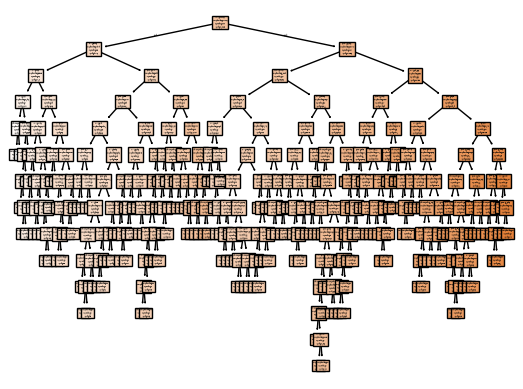

<Figure size 640x480 with 0 Axes>

In [33]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure()
plot_tree(arbol, feature_names=["TV", "radio", "newspaper"], filled=True)
plt.show()
plt.tight_layout()

In [37]:
from sklearn.model_selection import train_test_split

X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=67)


In [47]:
lr = LinearRegression()
lr.fit(X_train, y_train)

arbol = DecisionTreeRegressor()
arbol.fit(X_train, y_train)

tabla = pd.DataFrame({"R2 train": [lr.score(X_train, y_train), arbol.score(X_train, y_train)],
                      "R2 test": [lr.score(X_test, y_test), arbol.score(X_test, y_test)]},
                     index=["Regresion lineal", "Arbol"])
tabla

,R2 train,R2 test
Regresion lineal,0.914015,0.868902
Arbol,1.000000,0.931207
